# Portafolio 2/3 · Clasificación multiclase: especie de pingüino

Segundo modelo del portafolio. Mismo enfoque que en la regresión: línea base, varios candidatos, validación cruzada y confirmación en prueba.

Con un giro: el dataset de pingüinos es **tan separable** que casi cualquier algoritmo acierta casi todo. Eso hace difícil comparar. Por eso se evalúan dos escenarios:

- **A — las 4 medidas** (como en el ejercicio del curso).
- **B — solo la longitud de aleta**, como en el ejemplo simplificado del módulo 6. Aquí sí aparecen diferencias entre algoritmos.

Clases: 0 = Adelie, 1 = Gentoo, 2 = Barbijo (Chinstrap).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEMILLA = 42
ESPECIES = ['Adelie', 'Gentoo', 'Barbijo']
pinguinos = pd.read_csv('../datasets/penguins.csv')
print(f'{len(pinguinos)} filas · filas con alguna medida nula: {pinguinos.isna().any(axis=1).sum()}')

344 filas · filas con alguna medida nula: 2


## Preparación

Las filas nulas tienen **las cuatro medidas vacías**: no queda nada que imputar, así que se descartan. La proporción de especies no está equilibrada, así que los repartos se hacen **estratificados** (cada parte conserva la misma proporción).

In [2]:
pinguinos = pinguinos.dropna()
features = ['CulmenLength', 'CulmenDepth', 'FlipperLength', 'BodyMass']
y = pinguinos['Species']
print(f'{len(pinguinos)} pingüinos válidos')
y.value_counts(normalize=True).rename(index=dict(enumerate(ESPECIES))).round(3)

342 pingüinos válidos


Species
Adelie     0.442
Gentoo     0.360
Barbijo    0.199
Name: proportion, dtype: float64

## Candidatos

La regresión logística y el SVM se basan en magnitudes, y `BodyMass` (miles) aplastaría a `CulmenDepth` (decenas): llevan `StandardScaler` dentro del pipeline. Los árboles no lo necesitan.

| Algoritmo | Por qué está en la comparación |
|---|---|
| Clase más frecuente (`DummyClassifier`) | Línea base: siempre dice "Adelie" |
| Regresión logística | Clasificador lineal de referencia |
| Árbol de decisión | Reglas simples, interpretables |
| Bosque aleatorio | Conjunto de árboles |
| SVM | Busca la frontera con mayor margen entre clases |

In [3]:
def candidatos():
    escalar = lambda m: Pipeline([('escala', StandardScaler()), ('modelo', m)])
    return {
        'Clase más frecuente (línea base)': DummyClassifier(strategy='most_frequent'),
        'Regresión logística': escalar(LogisticRegression(max_iter=1000)),
        'Árbol de decisión': DecisionTreeClassifier(random_state=SEMILLA),
        'Bosque aleatorio': RandomForestClassifier(n_estimators=200, random_state=SEMILLA),
        'SVM': escalar(SVC(random_state=SEMILLA)),
    }

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def comparar(columnas):
    """Validación cruzada en entrenamiento + evaluación en prueba para un conjunto de features."""
    X_tr, X_te, y_tr, y_te = train_test_split(pinguinos[columnas], y, test_size=0.3,
                                              stratify=y, random_state=SEMILLA)
    filas, modelos = [], {}
    for nombre, modelo in candidatos().items():
        r = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=['accuracy', 'f1_macro'])
        modelo.fit(X_tr, y_tr)
        pred = modelo.predict(X_te)
        modelos[nombre] = modelo
        filas.append({'Modelo': nombre,
                      'Exactitud (CV)': r['test_accuracy'].mean(),
                      'F1 macro (CV)': r['test_f1_macro'].mean(),
                      'F1 desv. (CV)': r['test_f1_macro'].std(),
                      'Exactitud (prueba)': accuracy_score(y_te, pred),
                      'Precisión macro (prueba)': precision_score(y_te, pred, average='macro', zero_division=0),
                      'Recall macro (prueba)': recall_score(y_te, pred, average='macro'),
                      'F1 macro (prueba)': f1_score(y_te, pred, average='macro')})
    tabla = pd.DataFrame(filas).set_index('Modelo').sort_values(['F1 macro (CV)', 'F1 macro (prueba)'], ascending=False)
    return tabla, modelos, X_te, y_te

**¿Por qué F1 macro y no solo exactitud?** La exactitud puede engañar cuando las clases no están equilibradas (la trampa del 89% del módulo 5). El F1 *macro* calcula el F1 de cada especie por separado y los promedia sin ponderar, así que una especie mal clasificada pesa lo mismo aunque tenga pocos ejemplares.

## Escenario A — las 4 medidas

In [4]:
tabla_a, modelos_a, X_te_a, y_te_a = comparar(features)
tabla_a.round(3)

,Exactitud (CV),F1 macro (CV),F1 desv. (CV),Exactitud (prueba),Precisión macro (prueba),Recall macro (prueba),F1 macro (prueba)
Modelo,,,,,,,
Regresión logística,0.988,0.984,0.013,1.000,1.000,1.000,1.000
SVM,0.988,0.984,0.013,0.981,0.977,0.977,0.977
Bosque aleatorio,0.971,0.965,0.027,0.981,0.971,0.984,0.977
Árbol de decisión,0.941,0.930,0.032,0.981,0.971,0.984,0.977
Clase más frecuente (línea base),0.444,0.205,0.003,0.437,0.146,0.333,0.203


## Escenario B — solo la longitud de aleta (ejemplo del módulo 6)

In [5]:
tabla_b, modelos_b, X_te_b, y_te_b = comparar(['FlipperLength'])
tabla_b.round(3)

,Exactitud (CV),F1 macro (CV),F1 desv. (CV),Exactitud (prueba),Precisión macro (prueba),Recall macro (prueba),F1 macro (prueba)
Modelo,,,,,,,
Bosque aleatorio,0.778,0.679,0.031,0.748,0.664,0.670,0.664
Árbol de decisión,0.787,0.665,0.050,0.777,0.677,0.676,0.655
Regresión logística,0.812,0.652,0.070,0.786,0.684,0.675,0.643
SVM,0.795,0.620,0.040,0.786,0.696,0.683,0.662
Clase más frecuente (línea base),0.444,0.205,0.003,0.437,0.146,0.333,0.203


## Dónde se equivocan: matrices de confusión

Mejor modelo de cada escenario, sobre el conjunto de prueba.

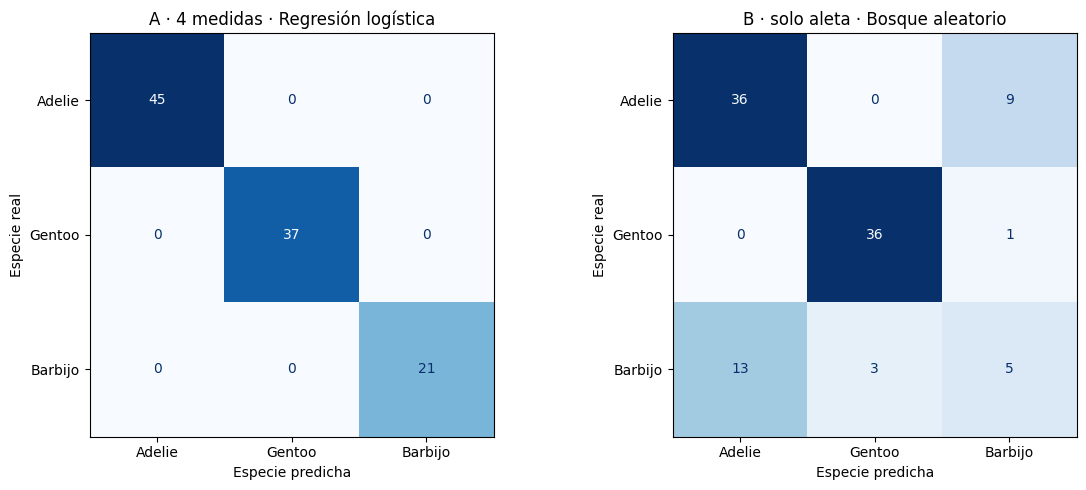

In [6]:
mejor_a, mejor_b = tabla_a.index[0], tabla_b.index[0]
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for eje, (titulo, modelo, X_te, y_te) in zip(ejes, [
        (f'A · 4 medidas · {mejor_a}', modelos_a[mejor_a], X_te_a, y_te_a),
        (f'B · solo aleta · {mejor_b}', modelos_b[mejor_b], X_te_b, y_te_b)]):
    ConfusionMatrixDisplay(confusion_matrix(y_te, modelo.predict(X_te)),
                           display_labels=ESPECIES).plot(ax=eje, cmap='Blues', colorbar=False)
    eje.set_title(titulo)
    eje.set_xlabel('Especie predicha')
    eje.set_ylabel('Especie real')
plt.tight_layout()
plt.savefig('../imagenes/clasificacion-matrices-confusion.png', dpi=110, bbox_inches='tight')
plt.show()

In [7]:
print(f'Escenario B · {mejor_b}\n')
print(classification_report(y_te_b, modelos_b[mejor_b].predict(X_te_b), target_names=ESPECIES, digits=3))

Escenario B · Bosque aleatorio

              precision    recall  f1-score   support

      Adelie      0.735     0.800     0.766        45
      Gentoo      0.923     0.973     0.947        37
     Barbijo      0.333     0.238     0.278        21

    accuracy                          0.748       103
   macro avg      0.664     0.670     0.664       103
weighted avg      0.721     0.748     0.732       103



## Casos de prueba del ejercicio

Con el mejor modelo del escenario A (el que usa las 4 medidas, como pide el ejercicio).

In [8]:
casos = pd.DataFrame({'CulmenLength': [45.2, 46.9], 'CulmenDepth': [15.4, 16.7],
                      'FlipperLength': [219, 189], 'BodyMass': [4753, 3645]}, index=['Caso 1', 'Caso 2'])
pred = modelos_a[mejor_a].predict(casos)
casos['Clase'] = pred
casos['Especie'] = [ESPECIES[c] for c in pred]
casos

,CulmenLength,CulmenDepth,FlipperLength,BodyMass,Clase,Especie
Caso 1,45.2,15.4,219,4753,1,Gentoo
Caso 2,46.9,16.7,189,3645,2,Barbijo


## Conclusiones

**Escenario A (4 medidas).** Todos los algoritmos superan con holgura la línea base (F1 macro 0.205). La regresión logística y el SVM empatan en validación cruzada (F1 macro 0.984) y la regresión logística acierta el 100% en prueba. Ante un empate, gana el más simple: **regresión logística**. El árbol de decisión, solo, es el más débil (0.930), y el bosque aleatorio lo mejora, como se espera de un conjunto.

**Escenario B (solo aleta).** El F1 macro cae a 0.62–0.68 para todos. El informe por clase muestra el porqué: Gentoo se sigue reconociendo bien (F1 0.947), pero **Barbijo apenas se detecta** (recall 0.238). La mayoría se confunde con Adelie: con la aleta sola, esas dos especies se solapan.

Lecciones del contraste:

- **Las features pesan más que el algoritmo.** Cambiar de algoritmo mueve el F1 unas centésimas; añadir las otras 3 medidas lo sube unos 0.3.
- **La exactitud esconde a la clase minoritaria.** En B, la regresión logística tiene la mejor exactitud en CV (0.812) pero el peor F1 macro entre los modelos reales (0.652): acierta mucho a costa de fallar con Barbijo, que es solo el 20% de los datos.
- **Sin un ganador claro, no hay que forzarlo.** En B el orden cambia entre CV y prueba, y las diferencias son menores que la desviación entre pliegues (0.03–0.07).

**Modelo elegido:** regresión logística con las 4 medidas.